# Which items go together on the twelve carts, and what does together mean?

**Week 4, Wednesday, chapter 1 of 3.** Swiggy Instamart, Pune, the cart page's frequently
bought together strip of three slots. On Monday 7 September 2026 the strip's ranking changed
from a curated list to the items most often found in the same cart as the items the cart
already holds. Toned milk sits in 71 percent of Pune carts and now appears beside nearly
everything. The strip's click-through fell from 6.1 percent in the three weeks before the
change to 3.8 percent in the three weeks after.

> Rank the pairs the strip should show, say why the click-through fell, and put a rupee
> value on a slot. Illustrative case: the company is real, the situation and the data are
> synthetic, built for this class.

**Who needs the answer.** The category manager, who proposes items for the strip, and the
growth lead, who will defend the fall at the Friday review.

**The questions on the way.** How often does a pair appear, how reliably does one item
bring the other, and does the pair beat chance.

**Setup.** Load the twelve printed carts from `../data/`. Each cart is a row with a 1 or
a 0 for every item. The shared helper, `c2kit`, provides `check` for PASS and FAIL lines
and `check_summary` for the total.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
twelve = pd.read_csv("../data/C2_W04_D03_twelve_rows_STUDENT.csv")
print("twelve printed carts, columns:", list(twelve.columns))
twelve

twelve printed carts, columns: ['cart_id', 'bananas', 'bread', 'chips', 'chocolate sauce', 'cold drink', 'coriander', 'curd', 'eggs', 'ice cream', 'onions', 'paneer', 'potatoes', 'tomatoes', 'toned milk']


,cart_id,bananas,bread,chips,chocolate sauce,cold drink,coriander,curd,eggs,ice cream,onions,paneer,potatoes,tomatoes,toned milk
0,TR01,1,1,0,0,0,1,0,1,0,1,0,1,0,1
1,TR02,1,1,0,0,0,0,1,1,0,0,0,0,0,1
2,TR03,0,1,0,0,0,0,1,0,0,1,1,0,0,1
3,TR04,0,1,0,0,0,0,0,1,0,0,0,0,1,1
4,TR05,0,0,1,0,1,0,0,1,0,1,0,0,0,1
5,TR06,0,0,1,0,1,1,0,0,0,0,0,0,0,1
6,TR07,1,0,0,0,0,0,0,0,0,1,0,1,0,1
7,TR08,0,0,0,0,0,1,0,0,0,0,1,0,1,1
8,TR09,0,0,1,0,0,1,0,0,0,1,0,1,0,0
9,TR10,1,0,0,0,1,0,1,0,0,0,0,0,1,0


## The map of where this notebook sits in the day

This notebook counts on twelve rows; the next one does the same count on 40,000 carts;
the third asks what each strip slot is worth; the lab notebook re-runs L1 to L3 on
Kalpa's own baskets.

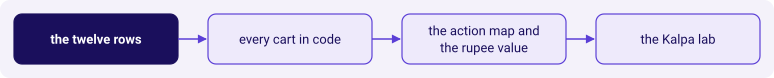

In [2]:
kit.flow(["the twelve rows",
          "every cart in code",
          "the action map and the rupee value",
          "the Kalpa lab"],
         lit=0, show=True)

## The toy: ten tea-stall orders

A tea stall holds the receipts for ten orders. Chai was in 6 orders, biscuit in 4, both in
3. The three questions can be read off those counts without a formula.

**Predict before you run.** Which of these three sentences is wrong?

- a) Support for the pair is 3 of 10, or 0.30.
- b) Confidence from chai to biscuit is 3 of 6, or 0.50.
- c) Lift is 1.25 and does not change when read from biscuit to chai.
- d) Lift of 1.25 means buying chai causes 25 percent more biscuit sales.

In [3]:
chai, biscuit, both, n = 6, 4, 3, 10
support = both / n
conf_chai_to_biscuit = both / chai
expected = (chai / n) * (biscuit / n) * n
lift = both / expected
print(f"support   {support:.2f}")
print(f"confidence (chai -> biscuit) {conf_chai_to_biscuit:.2f}")
print(f"expected if independent      {expected:.1f}")
print(f"lift                         {lift:.2f}")
kit.check("support reads 0.30", abs(support - 0.30) < 0.01)
kit.check("confidence reads 0.50", abs(conf_chai_to_biscuit - 0.50) < 0.01)
kit.check("lift is symmetric", abs(lift - (both * n) / (chai * biscuit)) < 1e-9)

support   0.30
confidence (chai -> biscuit) 0.50
expected if independent      2.4
lift                         1.25


**What happened.** The answer is d: lift of 1.25 does not say *chai causes biscuit sales*,
it says the pair is found together 25 percent more often than chance would predict. Lift
is a counting ratio, not a causal claim.

## The twelve printed carts

The twelve carts hold 14 named items between them. Count milk and bread first, then the
carts that hold both, and the three ratios bread to milk follow.

In [4]:
milk = int(twelve["toned milk"].sum())
bread = int(twelve["bread"].sum())
bread_milk = int(((twelve["toned milk"] == 1) & (twelve["bread"] == 1)).sum())
print(f"milk  in {milk} of 12")
print(f"bread in {bread} of 12")
print(f"both  in {bread_milk} of 12")
kit.check("milk in 8 carts",         milk == 8)
kit.check("bread in 4 carts",        bread == 4)
kit.check("every bread cart has milk", bread_milk == bread)

milk  in 8 of 12
bread in 4 of 12
both  in 4 of 12


## A quick picture of what the twelve carts hold

Count every item once across the twelve carts, draw the counts as a bar chart, and the
bread and milk pair's shape stands out. Milk and bread take the top two spots, and the
pair's four shared carts explain why the counts look the way they do.

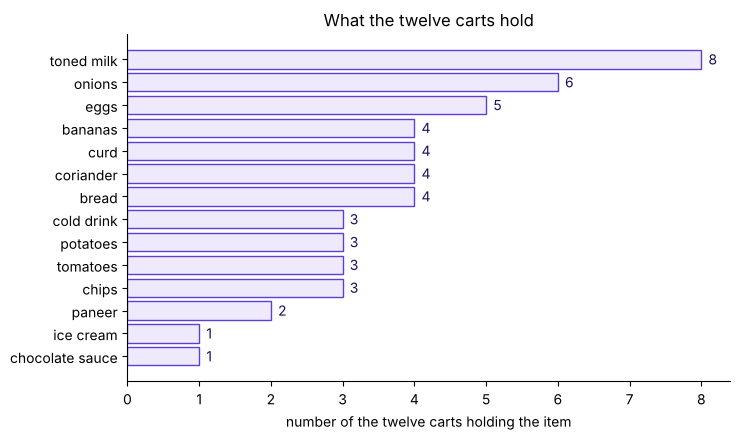

In [5]:
import matplotlib.pyplot as plt
counts = twelve.drop(columns=["cart_id"]).sum().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(counts.index, counts.values, color="#EEEAFB", edgecolor="#5B3FD6")
for i, v in enumerate(counts.values):
    ax.text(v + 0.1, i, str(int(v)), va="center", color="#1A0F5C", fontsize=10)
ax.set_xlabel("number of the twelve carts holding the item")
ax.set_title("What the twelve carts hold")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()
kit.check("the twelve-row item counts render", counts.sum() > 0)

## Bread to milk, the three numbers

Support is the share of the 12 carts with both. Confidence from bread to milk shrinks the
world to the 4 bread carts and asks how many of those also hold milk. Lift compares what
was seen with what independence would predict.

**Predict before you run.** Which value is highest?

- a) Support
- b) Confidence from bread to milk
- c) Lift
- d) Confidence from milk to bread

In [6]:
support = bread_milk / 12
conf_b_to_m = bread_milk / bread
expected_both = (bread / 12) * (milk / 12) * 12
lift = bread_milk / expected_both
conf_m_to_b = bread_milk / milk
print(f"support                  {support:.3f}")
print(f"confidence bread -> milk {conf_b_to_m:.3f}")
print(f"confidence milk -> bread {conf_m_to_b:.3f}")
print(f"lift                     {lift:.3f}")
kit.check("confidence bread -> milk is 1.00", abs(conf_b_to_m - 1.00) < 0.01)
kit.check("lift reads 1.50 within rounding",  abs(lift - 1.5) < 0.01)
kit.check("lift is symmetric",
          abs(lift - (bread_milk * 12) / (bread * milk)) < 1e-9)

support                  0.333
confidence bread -> milk 1.000
confidence milk -> bread 0.500
lift                     1.500


**What happened.** The answer is b: confidence reads 1.00 because every bread cart also
holds milk. Lift reads 1.50; milk was already in 8 of 12 carts, so the bread cart's milk
is only one and a half times more than independence would predict. Confidence toward a
popular item flatters the pair; lift divides the popularity out.

## Chips and cold drink on the twelve carts

Count the two items and the carts that hold both, then compute the three numbers again.

**Predict before you run.** Will the lift for chips and cold drink be higher than for
bread and milk, lower, or about the same?

In [7]:
chips = int(twelve["chips"].sum())
cold = int(twelve["cold drink"].sum())
cc = int(((twelve["chips"] == 1) & (twelve["cold drink"] == 1)).sum())
support_cc = cc / 12
conf_cc = cc / chips
lift_cc = cc / ((chips / 12) * (cold / 12) * 12)
print(f"chips in {chips}, cold in {cold}, together in {cc}")
print(f"support {support_cc:.3f}  confidence {conf_cc:.3f}  lift {lift_cc:.3f}")
kit.check("chips and cold both in 3 carts", chips == 3 and cold == 3)
kit.check("together in 2 carts",            cc == 2)
kit.check("lift reads 2.67 within rounding", abs(lift_cc - 2.667) < 0.01)

chips in 3, cold in 3, together in 2
support 0.167  confidence 0.667  lift 2.667


**What happened.** The lift for chips and cold drink reads 2.67, well above the 1.50 for
bread and milk, even though both pairs sit in only 2 or 4 of 12 carts. Lift lifts because
the two items are rarer on their own, so appearing together carries more information.

## The map of what each count hides, and what L2 adds

The twelve rows give three ratios the room can check with a pen. The next notebook runs
the same three numbers on 40,000 carts and finds two surprises the twelve rows cannot
show: a pair with high confidence and lift near one, and a pair with support so small the
count on 12 could not have found it at all.

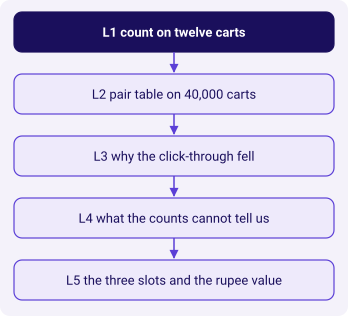

In [8]:
kit.vflow(["L1 count on twelve carts",
           "L2 pair table on 40,000 carts",
           "L3 why the click-through fell",
           "L4 what the counts cannot tell us",
           "L5 the three slots and the rupee value"],
          lit=0, show=True)

In [9]:
kit.check_summary()